# NumCompute-Stream — reproducible streaming demo
Run from repository root. The CSV is included in `demo/`. Prequential accuracy is evaluated before each update.

In [10]:
import sys
from pathlib import Path

project_root = Path.cwd()

if not (project_root / "numcompute_stream").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Package found:", (project_root / "numcompute_stream").is_dir())

import os
os.chdir(project_root)
print("Ready!")

Project root: C:\Users\91799\Downloads\NumCompute_Stream_Assignment_2_2\numcompute_stream_work
Package found: True
Ready!


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from numcompute_stream import DecisionTreeClassifier, StandardScaler, Imputer, Pipeline, StreamTrainer
from numcompute_stream.io import iter_csv_chunks
from numcompute_stream.visualise import plot_metric_over_time, compare_models, plot_predictions_vs_ground_truth


In [13]:
trainers = {
    60: StreamTrainer(Pipeline([('impute', Imputer()), ('scale', StandardScaler()), ('tree', DecisionTreeClassifier(max_depth=5, buffer_size=60))])),
    180: StreamTrainer(Pipeline([('impute', Imputer()), ('scale', StandardScaler()), ('tree', DecisionTreeClassifier(max_depth=5, buffer_size=180))]))
}
for data in iter_csv_chunks('demo/stream_data.csv', chunk_size=30, skip_header=1):
    X, y = data[:, :-1], data[:, -1].astype(int)
    for size, trainer in trainers.items():
        log = trainer.fit_chunk(X, y)
        print(f'buffer={size}, chunk={log["chunk"]}, prequential_accuracy={log["accuracy"]:.3f}, retrains={log["retrain_count"]}, memory={log["buffer_bytes"]} bytes')


buffer=60, chunk=1, prequential_accuracy=nan, retrains=0, memory=720 bytes
buffer=180, chunk=1, prequential_accuracy=nan, retrains=0, memory=720 bytes
buffer=60, chunk=2, prequential_accuracy=nan, retrains=1, memory=0 bytes
buffer=180, chunk=2, prequential_accuracy=nan, retrains=0, memory=1440 bytes
buffer=60, chunk=3, prequential_accuracy=0.933, retrains=1, memory=720 bytes
buffer=180, chunk=3, prequential_accuracy=nan, retrains=0, memory=2160 bytes
buffer=60, chunk=4, prequential_accuracy=0.900, retrains=2, memory=0 bytes
buffer=180, chunk=4, prequential_accuracy=nan, retrains=0, memory=2880 bytes
buffer=60, chunk=5, prequential_accuracy=0.900, retrains=2, memory=720 bytes
buffer=180, chunk=5, prequential_accuracy=nan, retrains=0, memory=3600 bytes
buffer=60, chunk=6, prequential_accuracy=0.900, retrains=3, memory=0 bytes
buffer=180, chunk=6, prequential_accuracy=nan, retrains=1, memory=0 bytes
buffer=60, chunk=7, prequential_accuracy=0.933, retrains=3, memory=720 bytes
buffer=180, c

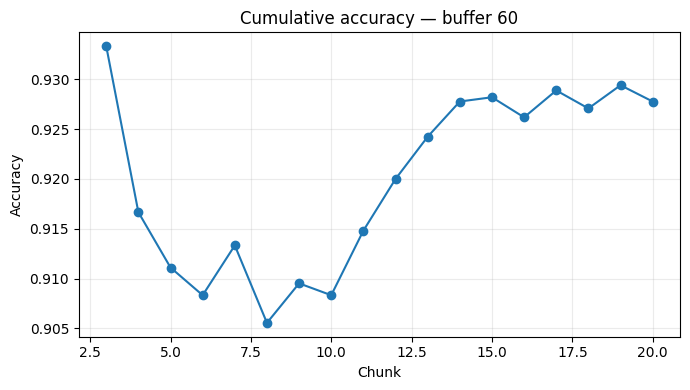

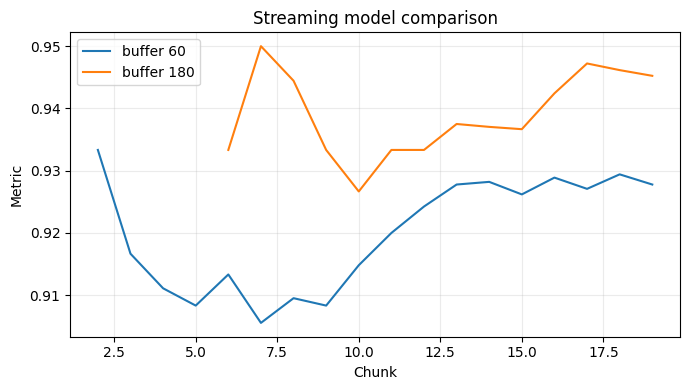

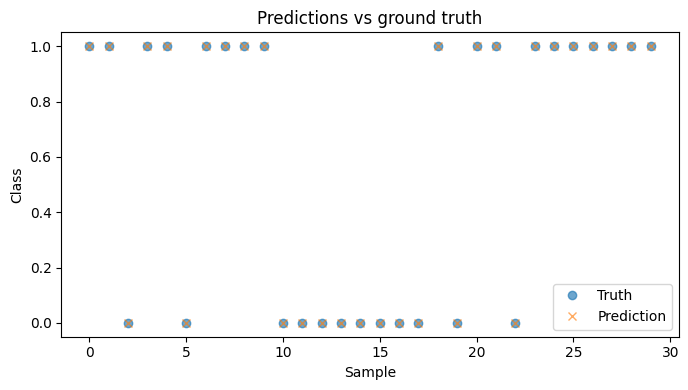

Final cumulative metrics: {60: {'count': 540, 'accuracy': 0.9277777777777778, 'precision': 0.9348659003831418, 'recall': 0.9172932330827067, 'f1': 0.9259962049335864, 'error': 0.07222222222222219, 'confusion_matrix': array([[257,  17],
       [ 22, 244]]), 'auc': nan}, 180: {'count': 420, 'accuracy': 0.9452380952380952, 'precision': 0.9423076923076923, 'recall': 0.9468599033816425, 'f1': 0.944578313253012, 'error': 0.05476190476190479, 'confusion_matrix': array([[201,  12],
       [ 11, 196]]), 'auc': nan}}


In [14]:
series={size:[row['cumulative_accuracy'] for row in trainer.history] for size,trainer in trainers.items()}
plot_metric_over_time(series[60], 'Cumulative accuracy — buffer 60', 'Accuracy', save_path='demo/accuracy.png')
compare_models(series[60], series[180], labels=('buffer 60','buffer 180'), save_path='demo/comparison.png')
last = trainers[60].model.predict(X)
plot_predictions_vs_ground_truth(y,last,save_path='demo/predictions.png')
plt.show()
print('Final cumulative metrics:', {size: t.metrics.result() for size,t in trainers.items()})


## Interpretation
The first chunks have no accuracy until the buffer first fills. Increasing buffer size reduces retraining frequency but delays model updates. Data are synthetic and results are illustrative, not a clinical or real-world benchmark.